# 04 · Neural network (Multi-Layer Perceptron)

A neural network can learn non-linear patterns (e.g. "online + new merchant + night-time" together). We use scikit-learn's `MLPClassifier` so the whole project runs without installing TensorFlow — the ideas are the same as a Keras `Sequential` model with `Dense` layers.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # so we can import src/utils.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from src.utils import *   # load_data, time_split, make_preprocessor, evaluate, ...

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 4.5)

In [2]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import average_precision_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler

df = load_data()
train, val, test = time_split(df)
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

## 1. A bug worth knowing about

In the original project, predictions were made with `model.predict(X).astype(int)`. `predict` returns **probabilities** like 0.83, and `.astype(int)` chops off the decimal → **every prediction becomes 0**. That's why their first network "caught" no fraud. Always convert probabilities with a threshold:

In [3]:
probs = np.array([0.02, 0.51, 0.83, 0.99])
print("astype(int):     ", probs.astype(int))          # [0 0 0 0]  <- wrong
print(">= 0.5 threshold:", (probs >= 0.5).astype(int))  # [0 1 1 1]  <- right

astype(int):      [0 0 0 0]
>= 0.5 threshold: [0 1 1 1]


## 2. Network without any imbalance handling

--- MLP - plain (threshold 0.5) ---
                accuracy: 0.9985
               precision: 0.7895
   recall (fraud caught): 0.4167
                      f1: 0.5455
     false_negative_rate: 0.5833
           frauds_missed: 42
            false_alarms: 8
                  pr_auc: 0.5453
                 roc_auc: 0.9582
                cost_gbp: 3,099.0000


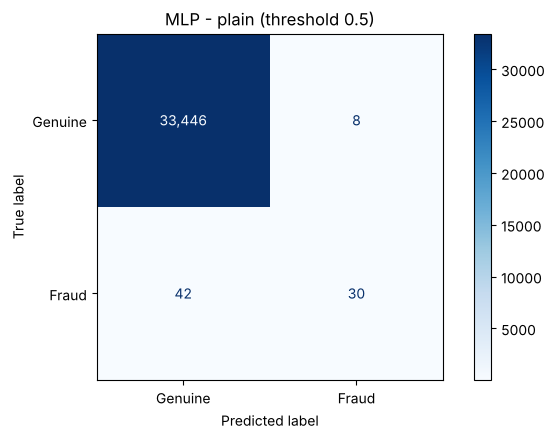

In [4]:
def mlp(hidden=(32, 16), alpha=1e-4):
    # early_stopping keeps 10% of training data aside and stops when it stops improving (avoids overfitting)
    return MLPClassifier(hidden_layer_sizes=hidden, activation="relu", alpha=alpha,
                         early_stopping=True, max_iter=200, random_state=RANDOM_STATE)

plain = ImbPipeline([("prep", make_preprocessor()), ("model", mlp())]).fit(X_train, y_train)
p_val = plain.predict_proba(X_val)[:, 1]
_ = evaluate("MLP - plain (threshold 0.5)", y_val, (p_val >= 0.5).astype(int), p_val, val["amount_gbp"])

## 3. With oversampling

`MLPClassifier` has no `class_weight` option, so we balance the training data instead. We try SMOTE and simple random oversampling (duplicating fraud rows), **only inside the training pipeline**.

We tune on validation PR-AUC: the sampler, the layer sizes and `alpha` (L2 regularisation — like `C` in logistic regression, but the other way round: bigger alpha = simpler model).

In [5]:
rows, models = [], {}
for sampler_name, sampler in [("SMOTE", SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE)),
                              ("RandomOver", RandomOverSampler(sampling_strategy=0.1, random_state=RANDOM_STATE))]:
    for hidden in [(16,), (32, 16), (64, 32)]:
        for alpha in [1e-4, 1e-2]:
            pipe = ImbPipeline([("prep", make_preprocessor()), ("sampler", sampler),
                                ("model", mlp(hidden, alpha))]).fit(X_train, y_train)
            score = average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1])
            rows.append({"sampler": sampler_name, "hidden_layers": hidden, "alpha": alpha, "val_pr_auc": score})
            models[(sampler_name, hidden, alpha)] = pipe
nn_table = pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False)
nn_table

,sampler,hidden_layers,alpha,val_pr_auc
11,RandomOver,"(64, 32)",0.0100,0.567033
8,RandomOver,"(32, 16)",0.0001,0.553238
9,RandomOver,"(32, 16)",0.0100,0.531291
5,SMOTE,"(64, 32)",0.0100,0.516149
4,SMOTE,"(64, 32)",0.0001,0.512088
7,RandomOver,"(16,)",0.0100,0.482265
6,RandomOver,"(16,)",0.0001,0.479444
1,SMOTE,"(16,)",0.0100,0.477007
3,SMOTE,"(32, 16)",0.0100,0.471981
2,SMOTE,"(32, 16)",0.0001,0.459906


`sampling_strategy=0.1` means "oversample until fraud is 10% the size of genuine", rather than a full 50/50 — making ~100× copies of a few hundred frauds tends to overfit.

In [6]:
best = nn_table.iloc[0]
final_nn = models[(best["sampler"], best["hidden_layers"], best["alpha"])]
p_val = final_nn.predict_proba(X_val)[:, 1]
threshold = best_threshold(y_val, p_val, val["amount_gbp"])
print(f"Best: {best['sampler']}, layers={best['hidden_layers']}, alpha={best['alpha']}, threshold={threshold}")

Best: RandomOver, layers=(64, 32), alpha=0.01, threshold=0.09


## 4. Final score on the TEST set

--- Neural network (final) ---
                accuracy: 0.9958
               precision: 0.3529
   recall (fraud caught): 0.6429
                      f1: 0.4557
     false_negative_rate: 0.3571
           frauds_missed: 40
            false_alarms: 132
                  pr_auc: 0.5630
                 roc_auc: 0.9587
                cost_gbp: 5,254.2400


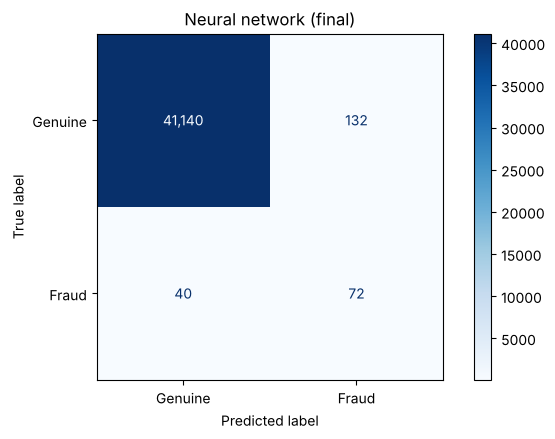

In [7]:
p_test = final_nn.predict_proba(X_test)[:, 1]
nn_results = evaluate("Neural network (final)", y_test, (p_test >= threshold).astype(int), p_test, test["amount_gbp"])

In [8]:
import json, os
os.makedirs("../results", exist_ok=True)
json.dump({k: (float(v) if not isinstance(v, str) else v) for k, v in nn_results.items()} | {"threshold": threshold},
          open("../results/neural_network.json", "w"), indent=2)

## Summary
- Converting probabilities with `.astype(int)` silently gives all zeros — always use a threshold.
- The network needs imbalance handling and regularisation; it is harder to explain than logistic regression.
- On tabular data like this, neural networks often do **not** beat tree models (see notebook 05).